# Libraries

In [ ]:
!pip install haversine

In [ ]:
!pip install osmnx folium numpy matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.5/107.5 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 38.8 MB/s eta 0:00:00
  Attempting uninstall: networkx
    Found existing installation: networkx 3.4.1
    Uninstalling networkx-3.4.1:
      Successfully uninstalled networkx-3.4.1
  Attempting uninstall: geopandas
    Found existing installation: geopandas 1.0.1
    Uninstalling geopandas-1.0.1:
      Successfully uninstalled geopandas-1.0.1


In [ ]:
import os
os.sys.path.append('/content/drive/MyDrive/Colab Notebooks')

from datetime import timedelta
import geopandas as gpd

import numpy as np
import matplotlib.pyplot as plt
import osmnx as ox
import pandas as pd
from shapely.geometry import Point, Polygon

from datetime import datetime
import folium
import requests
import urllib.parse


In [ ]:
from google.colab import drive
from google.colab import files
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Dispersion

Road-link emissions are not the same as the concentration a person breathes.
This section spreads the estimated link emissions over space with a Gaussian
plume model, producing a grid of CO2 concentration values.


# Concentration Map

The grid below is the dispersion model's estimate of CO2 concentration over the
central area of Pisa. Later sections sample this grid to estimate exposure at
schools and along walking routes.


In [ ]:
city = 'Pisa'
path = '/content/drive/MyDrive/Colab Notebooks/phd_data/'
date = '06_21_2024'

embs_n_co2m = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/phd_data/{}_embs_n_co2m.csv'.format(city.lower()))
embs_n_co2m = embs_n_co2m[['start_point', 'end_point', 'CO_2/m']]
embs_n_co2m = embs_n_co2m[embs_n_co2m['CO_2/m']<=100]

embs_with_predictions = pd.read_csv(path+'xgb_xgb/mdi_preds_{}_{}_125.csv'.format(city.lower(), date))
embs_with_predictions = embs_with_predictions.rename(columns={'predicted_carbon':'CO_2/m'})
embs_with_predictions = embs_with_predictions[['start_point', 'end_point', 'CO_2/m']]

embs_all = pd.concat([embs_with_predictions, embs_n_co2m], ignore_index=True)

embs_n_co2m = embs_n_co2m.rename(columns={'start_point':'s_id', 'end_point':'e_id', 'CO_2/m':'emission_amount'})
df = embs_n_co2m[['s_id', 'e_id', 'emission_amount']]
df['emission_amount'] = df['emission_amount'] / 365 / 24 / 60  # Annual amount converted to a minute average.

print(len(df))
print(np.min(df.emission_amount), np.max(df.emission_amount))
df.head()


30719
2.358085491105974e-09 0.0001840908819622425


,s_id,e_id,emission_amount
0,7257369708,31770729,5.068239e-07
1,33681447,3044082602,1.007998e-06
2,3044082602,6957424170,4.562248e-07
3,6957424170,9986411817,3.620026e-07
4,213417023,9986411817,6.685588e-07


In [ ]:
edge_lens = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/phd_data/OSM_{}_raw_segment'.format(city))
edge_lens = edge_lens[['s_id', 'e_id', 'length']]
edge_lens.head()

,s_id,e_id,length
0,31770729,7257369708,6.135
1,7257369708,31770729,6.135
2,33681447,3044082602,15.567
3,3044082602,6957424170,16.040
4,6957424170,9986411817,9.738


In [ ]:
df = pd.merge(df, edge_lens, on=['s_id', 'e_id'])
df['emission_amount'] = df['emission_amount'] * df['length']
df = df.drop(['length'], axis=1)
print(len(df))
df.head()

30719


,s_id,e_id,emission_amount
0,7257369708,31770729,0.000003
1,33681447,3044082602,0.000016
2,3044082602,6957424170,0.000007
3,6957424170,9986411817,0.000004
4,213417023,9986411817,0.000005


In [ ]:
print(np.min(df.emission_amount), np.max(df.emission_amount))


6.164383561643764e-07 0.09133988620808263


In [ ]:
# Define the location and network type
location = 'Pisa, Italy'
network_type = 'drive_service'

# Define grid parameters
cell_size = 5  # Cell size in meters

# Fetch the boundary and bounding box for Pisa

central_area = (43.7295, 43.7025, 10.4214, 10.3824)  # Specify the central area of Pisa (3x3 km)
ymax, ymin, xmax, xmin = central_area
road = ox.graph_from_bbox(bbox=(ymax, ymin, xmax, xmin), network_type='drive_service',
                          retain_all=True, truncate_by_edge=True, simplify=False)

G_proj = ox.project_graph(road)
gdfs = ox.graph_to_gdfs(G_proj)
gdfs[1].reset_index(inplace=True)
roads_with_geometries = gdfs[1]
roads_with_geometries = roads_with_geometries.rename(columns={'u':'s_id', 'v':'e_id'})

roads_with_geometries = roads_with_geometries.merge(df, on=['s_id', 'e_id'])
print("There are %s road segments with emission in the map" %len(roads_with_geometries))


There are 8750 road segments with emission in the map


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from shapely.geometry import Point, LineString
import random
from pyproj import Transformer


# Dispersion parameters
D = 1  # Diffusion coefficient (m^2/s)
H = 0.5  # Initial height of emission (m)
minutes_per_hour = 60
sigma_z = 0.76 * H  # Vertical dispersion coefficient (m)

# Create a transformer from UTM (assuming UTM zone 32N, EPSG:32632) to WGS84
transformer = Transformer.from_crs("epsg:32632", "epsg:4326", always_xy=True)

# Function to calculate concentration using Gaussian model without wind

def gaussian_concentration(Q, sigma_y, sigma_z, x, y, H):
    # calculate time-integrated concentration at x, y, z
    dist = np.sqrt(x**2 + y**2)
    z = H
    f = np.exp(-(dist**2./(2.*sigma_y**2)))

    g1 = np.exp(-((z - H)**2./(2.*sigma_z**2)))
    g2 = np.exp(-((z + H)**2./(2.*sigma_z**2)))
    return Q * f/(sigma_y*np.sqrt(2.*np.pi)) * (g1 + g2)/(sigma_z*np.sqrt(2.*np.pi))




# Create the map grid
x_map_grid = np.arange(xmin, xmax, cell_size/100000)
y_map_grid = np.arange(ymin, ymax, cell_size/100000)
X_map, Y_map = np.meshgrid(x_map_grid, y_map_grid)
map_grid_shape = X_map.shape
concentration_map_grid = np.zeros(map_grid_shape)

# Define emission sources based on road segments
num_emission_sources = 0
emission_sources = []

# Iterate over the DataFrame rows
for idx, row in roads_with_geometries.iterrows():
    s_id = row['s_id']
    e_id = row['e_id']
    emission_amount = row['emission_amount']

    geometry = row['geometry']
    line = LineString(geometry)

    road_length = line.length

    num_points = int(road_length) + 1

    emission_per_point = emission_amount / num_points

    for distance in np.linspace(start=0, stop=int(road_length), num=num_points):
        point = line.interpolate(distance)
        x, y = transformer.transform(point.x, point.y)  # UTM to WGS84
        emission_sources.append((x, y, emission_per_point))
        num_emission_sources += 1

print("The number of emission sources is %s" %num_emission_sources)

# Precompute the emission grid for a single point
grid_radius = int(np.sqrt(2 * D * minutes_per_hour * 60) * 3)  # 3 standard deviations to capture most of the distribution
emission_grid_size = int(2 * grid_radius / cell_size) + 1

x_emission_grid = np.linspace(-grid_radius, grid_radius, emission_grid_size)
y_emission_grid = np.linspace(-grid_radius, grid_radius, emission_grid_size)

X_emission, Y_emission = np.meshgrid(x_emission_grid, y_emission_grid)

# Calculate concentration values for the emission grid over 60 minutes
accumulated_emission_grid = np.zeros_like(X_emission)

for minute in range(1, minutes_per_hour + 1):
    time = minute * 60  # Convert minutes to seconds
    sigma_y = np.sqrt(2 * D * time)  # Horizontal dispersion coefficient (m)
    emission_grid = gaussian_concentration(1, sigma_y, sigma_z, X_emission, Y_emission, H)
    accumulated_emission_grid += emission_grid

# Function to add emission grid to the map grid
def add_emission_to_map(concentration_map, emission_grid, pr, pc, scale_factor):
    grid_size = emission_grid.shape[0]
    for i in range(grid_size):
        for j in range(grid_size):
            if 0 <= pr + i < concentration_map.shape[0] and 0 <= pc + j < concentration_map.shape[1]:
                concentration_map[pr + i, pc + j] += emission_grid[i, j] * scale_factor


# Add emission grids to the map grid
for source in emission_sources:
    x, y, rate = source
    # Calculate the position in the map grid
    pr = int((y - ymin) / (ymax - ymin) * map_grid_shape[0])
    pc = int((x - xmin) / (xmax - xmin) * map_grid_shape[1])

    # Add the scaled emission grid to the map grid
    add_emission_to_map(concentration_map_grid, accumulated_emission_grid, pr - emission_grid_size // 2, pc - emission_grid_size // 2, rate)



The number of emission sources is 198532


In [ ]:
print("Minimum: %s\nMaximum: %s\nMean: %s" %(np.min(concentration_map_grid), np.max(concentration_map_grid), np.mean(concentration_map_grid)))


Minimum: 0.0
Maximum: 0.004934669300394761
Mean: 0.0003318534384155065


In [ ]:
# Fill zero cells with the smallest non-zero value for log plotting.
non_zero_values = concentration_map_grid[concentration_map_grid != 0]
min_non_zero_value = non_zero_values.min()
print(min_non_zero_value)

# Leave non-zero concentrations unchanged.
concentration_map_grid = np.where(concentration_map_grid == 0, min_non_zero_value, concentration_map_grid)

1.0029083876740059e-11


## Plot the Map

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Minimum cell concentration:1.0029083876740059e-11
Maximum cell concentraation:0.004934669300394761



(<Figure size 1000x1000 with 2 Axes>,
 <Axes: xlabel='Longitude', ylabel='Latitude'>)

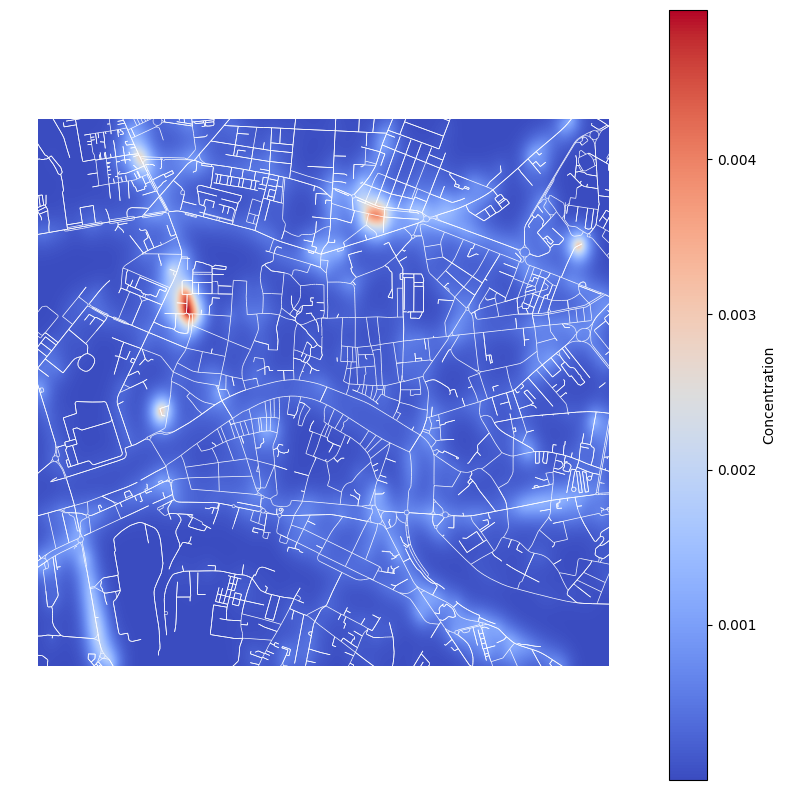

In [ ]:

# Supplementary linear-scale map (not in the paper); the paper uses the log-transformed maps.
central_area = (43.7295, 43.7025, 10.4214, 10.3824)  # Specify the central area of Pisa (3x3 km)
ymax, ymin, xmax, xmin = central_area
road = ox.graph_from_bbox(bbox=(ymax, ymin, xmax, xmin), network_type='drive_service',
                          retain_all=True, truncate_by_edge=True, simplify=False)

emissions = 'original' # original/all
output_path = '/content/drive/MyDrive/Colab Notebooks/phd_data/'  # Restricted data path from the original Colab runs.

concentration_map_grid = np.load(output_path + 'minute_concentration_map_pisa_3x3_{}_below_100.npy'.format(emissions))
print("Minimum cell concentration:%s\nMaximum cell concentraation:%s\n" %(np.min(concentration_map_grid), np.max(concentration_map_grid)))

# Define new color scale limits
vmin = 1.0029083876740059e-11  # minimum value for the color bar
vmax = 0.004961519509492084  # maximum value for the color bar


# Plot the concentration grid
plt.figure(figsize=(10, 10))
plt.imshow(concentration_map_grid, cmap='coolwarm', origin='lower', vmin=vmin, vmax=vmax, extent=[xmin, xmax, ymin, ymax])
plt.colorbar(label='Concentration')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)

# Plot emission points on the road network

# Download and plot the road network
ox.plot_graph(road, ax=plt.gca(), node_color='none', bgcolor='w', node_size=0, edge_color='white', edge_linewidth=0.5, show=False, close=False)

Minimum cell concentration:-17.955640927491192
Maximum cell concentraation:-5.306043232441535

-17.955640927491192 -5.306043232441535


(<Figure size 1000x1000 with 2 Axes>,
 <Axes: xlabel='Longitude', ylabel='Latitude'>)

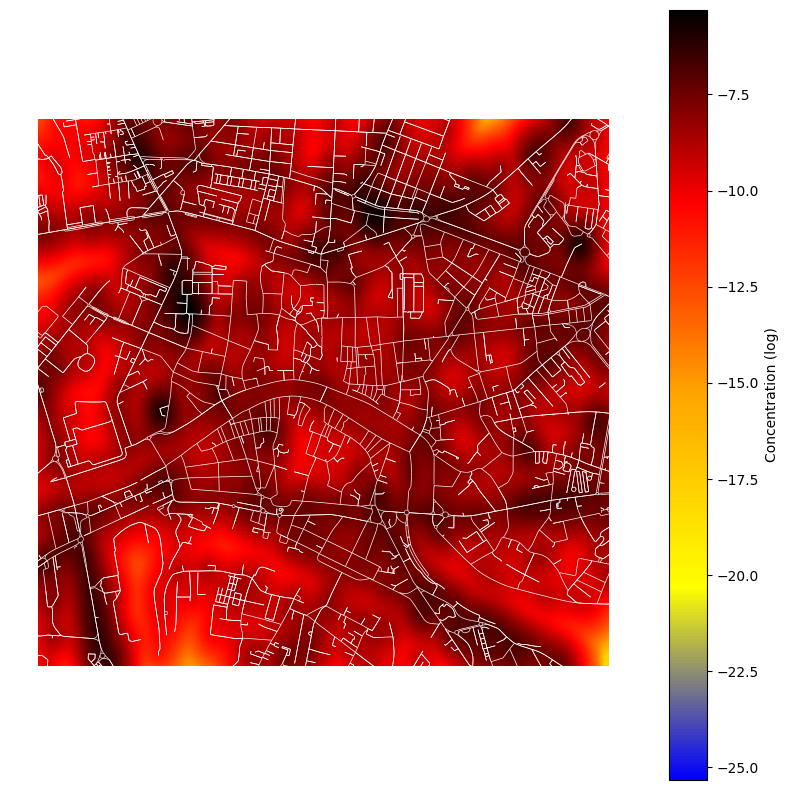

In [ ]:
from matplotlib.colors import LinearSegmentedColormap



central_area = (43.7295, 43.7025, 10.4214, 10.3824)  # Specify the central area of Pisa (3x3 km)
ymax, ymin, xmax, xmin = central_area
road = ox.graph_from_bbox(bbox=(ymax, ymin, xmax, xmin), network_type='drive_service',
                          retain_all=True, truncate_by_edge=True, simplify=False)

emissions = 'all' # original/all
output_path = '/content/drive/MyDrive/Colab Notebooks/phd_data/'  # Restricted data path from the original Colab runs.

concentration_map_grid = np.load(output_path + 'minute_concentration_map_pisa_3x3_{}_below_100.npy'.format(emissions))
log_concentration_map_grid = np.log(concentration_map_grid)
print("Minimum cell concentration:%s\nMaximum cell concentraation:%s\n" %(np.min(log_concentration_map_grid), np.max(log_concentration_map_grid)))


# Define new color scale limits
vmin = -25.32553185643736  # minimum value for the color bar
vmax = -5.306043232441535  # maximum value for the color bar
print(np.min(log_concentration_map_grid), np.max(log_concentration_map_grid))
# Define custom colormap (blue, yellow, orange, red, black)
cmap = LinearSegmentedColormap.from_list('custom_colormap', ['blue', 'yellow', 'orange', 'red', 'black'])

# Plot the concentration grid
plt.figure(figsize=(10, 10))
plt.imshow(log_concentration_map_grid, cmap=cmap, origin='lower', vmin=vmin, vmax=vmax, extent=[xmin, xmax, ymin, ymax])
plt.colorbar(label='Concentration (log)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)

# Plot emission points on the road network

# Download and plot the road network
ox.plot_graph(road, ax=plt.gca(), node_color='none', bgcolor='w', node_size=0, edge_color='white', edge_linewidth=0.5, show=False, close=False)

# Exposure

Static exposure is estimated by reading the concentration at each school's
location and multiplying by an assumed occupancy period. This is an estimate of
inhaled CO2, not a sensor measurement.


In [ ]:
# Get schools within the bounding box
tags = {'amenity': 'school'}
schools = ox.geometries_from_bbox(ymax, ymin, xmax, xmin, tags)

# Convert to UTM coordinates

print(f"\nThere are {len(schools)} schools in Pisa.")


<ipython-input-11-593d44ea99dd>:3: FutureWarning: The `geometries` module and `geometries_from_X` functions have been renamed the `features` module and `features_from_X` functions. Use these instead. The `geometries` module and function names are deprecated and will be removed in the v2.0.0 release. See the OSMnx v2 migration guide: https://github.com/gboeing/osmnx/issues/1123
  schools = ox.geometries_from_bbox(ymax, ymin, xmax, xmin, tags)
/usr/local/lib/python3.10/dist-packages/osmnx/geometries.py:48: FutureWarning: The `north`, `south`, `east`, and `west` parameters are deprecated and will be removed in the v2.0.0 release. Use the `bbox` parameter instead. See the OSMnx v2 migration guide: https://github.com/gboeing/osmnx/issues/1123
  return features.features_from_bbox(north, south, east, west, tags=tags)



There are 37 schools in Pisa.


In [ ]:
# Function to get concentration from the precomputed grid
def get_concentration_from_grid(concentration_map, x, y, xmin, xmax, ymin, ymax):
    pr = int((y - ymin) / (ymax - ymin) * concentration_map.shape[0])
    pc = int((x - xmin) / (xmax - xmin) * concentration_map.shape[1])
    if 0 <= pr < concentration_map.shape[0] and 0 <= pc < concentration_map.shape[1]:
        return concentration_map[pr, pc]
    else:
        return 0


In [ ]:
concentration_map_grid_copy = concentration_map_grid * 24 * 365

# Calculate concentration at each school within the 2x2 km area
school_concentrations = []
for idx, school in schools.iterrows():
    point = school.geometry

    # Check if the geometry is a point or a polygon
    if isinstance(point, Point):
        school_x, school_y = point.x, point.y
    elif isinstance(point, Polygon):
        centroid = point.centroid
        school_x, school_y = centroid.x, centroid.y
    else:
        # Skip if geometry type is not handled
        continue

    concentration = get_concentration_from_grid(concentration_map_grid_copy, school_x, school_y, xmin, xmax, ymin, ymax)
    school_concentrations.append((school['name'], school_x, school_y, concentration))

# Store the concentration sampled at each school.


Number of schools: 36
Mean concentration: 2.21
Median concentration: 1.71
Max concentration: 6.87
Min concentration: 0.00
Standard deviation of concentration: 1.72


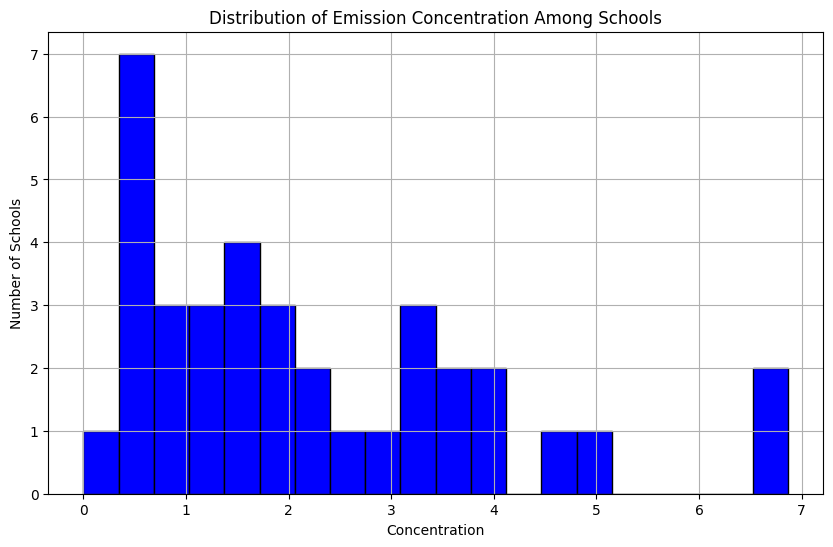

In [ ]:
# Convert to a DataFrame for easier analysis
school_concentration_df = pd.DataFrame(school_concentrations, columns=['school_name', 'school_x', 'school_y', 'concentration'])

# Count the number of schools
num_schools = len(school_concentration_df)

# Calculate basic statistics
mean_concentration = school_concentration_df['concentration'].mean()
median_concentration = school_concentration_df['concentration'].median()
max_concentration = school_concentration_df['concentration'].max()
min_concentration = school_concentration_df['concentration'].min()
std_concentration = school_concentration_df['concentration'].std()

# Print the statistics
print(f"Number of schools: {num_schools}")
print(f"Mean concentration: {mean_concentration:.2f}")
print(f"Median concentration: {median_concentration:.2f}")
print(f"Max concentration: {max_concentration:.2f}")
print(f"Min concentration: {min_concentration:.2f}")
print(f"Standard deviation of concentration: {std_concentration:.2f}")

# Plot the concentration distribution among schools
plt.figure(figsize=(10, 6))
plt.hist(school_concentration_df['concentration'], bins=20, color='blue', edgecolor='black')
plt.xlabel('Concentration')
plt.ylabel('Number of Schools')
plt.title('Distribution of Emission Concentration Among Schools')
plt.grid(True)
plt.show()

In [ ]:
# Rank the schools based on concentration
school_concentration_df['rank'] = school_concentration_df['concentration'].rank(method='min', ascending=False).astype(int)
school_concentration_df = school_concentration_df.sort_values('rank')
school_concentration_df['concentration'] = np.exp(school_concentration_df['concentration'])

# Print ranked schools
school_concentration_df

,school_name,school_x,school_y,concentration,rank
7,Scuola Primaria De Sanctis,10.415800,43.712802,958.818135,1
34,"Scuola Primaria ""Biagi""",10.385646,43.709495,796.991285,2
3,Santa Caterina,10.404116,43.721462,142.700671,3
11,Scuola Primaria D. Chiesa,10.408033,43.718319,87.038512,4
21,"IPSSAR ""Giacomo Matteotti""",10.417732,43.717126,48.462176,5
2,"Liceo Classico ""Galileo Galilei""",10.402882,43.710677,44.629666,6
0,"Liceo scientifico ""Ulisse Dini""",10.401278,43.710799,39.932977,7
31,"Scuole Elementari ""De Sanctis""",10.415647,43.712410,34.682448,8
12,"IPSIA ""Fascetti""",10.393784,43.726743,27.929158,9
33,Scuola Primaria “C. Battisti”,10.404682,43.707367,27.554315,10


In [ ]:
# Extract the five schools with the highest concentrations
top_10_schools = school_concentration_df.nlargest(5, 'concentration')

# Extract the five schools with the lowest concentrations
bottom_10_schools = school_concentration_df.nsmallest(5, 'concentration')

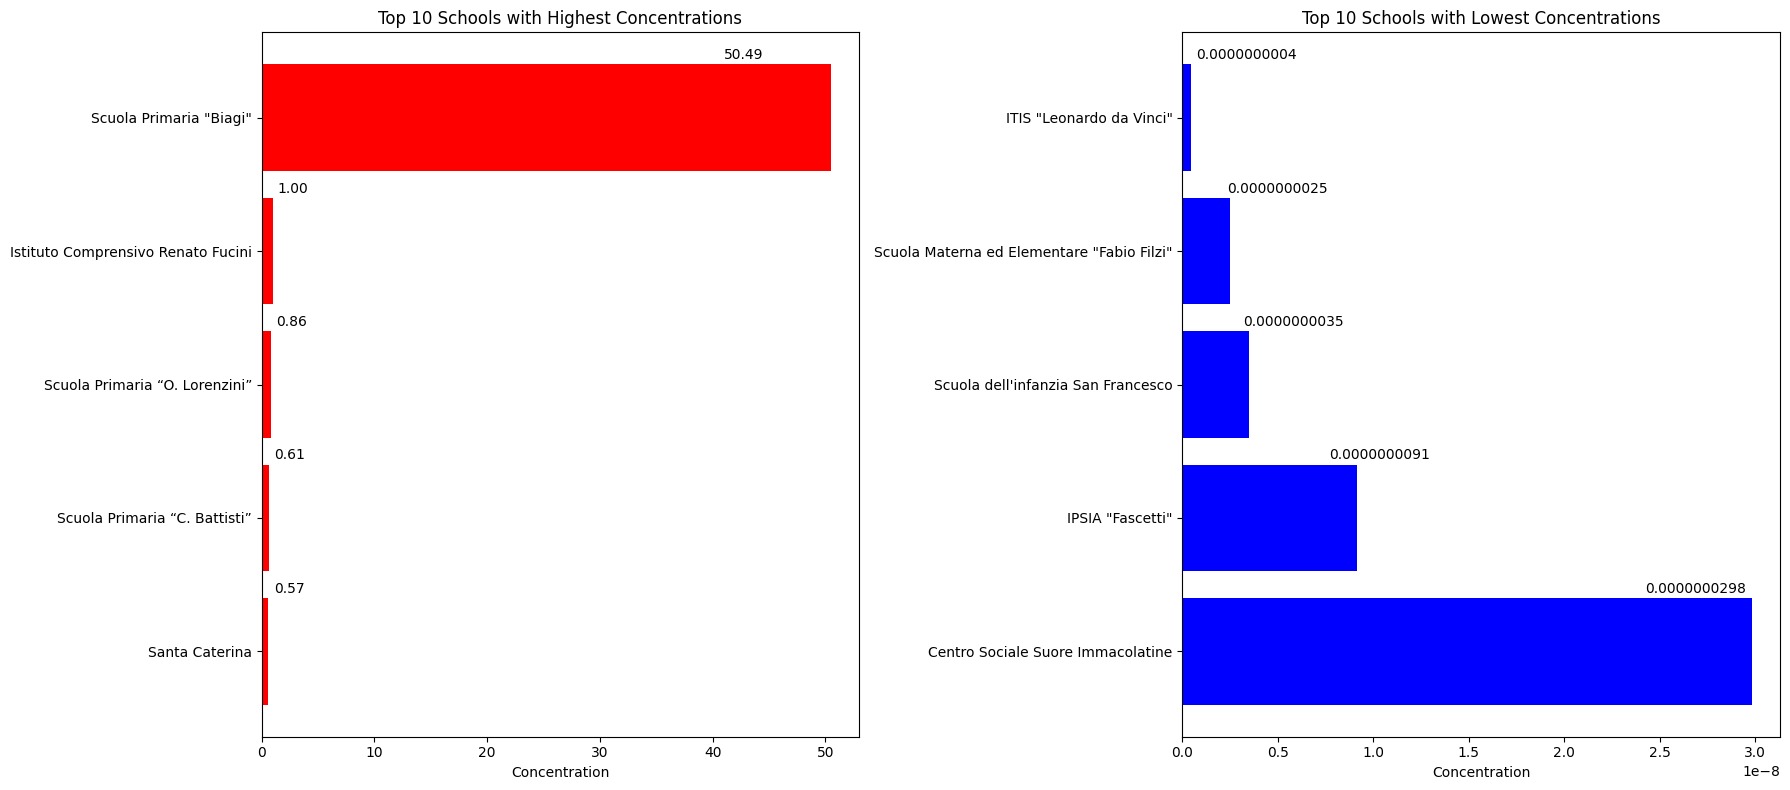

In [ ]:
# Set up the figure and axes for the bar plots
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 8))

# Bar plot for the highest-concentration schools
bars_top = axes[0].barh(top_10_schools['school_name'], top_10_schools['concentration'], color='red')
axes[0].set_title('Top 10 Schools with Highest Concentrations')
axes[0].set_xlabel('Concentration')
axes[0].invert_yaxis()  # Highest concentration on top

# Annotate bars with concentration values
for bar in bars_top:
    width = bar.get_width()
    axes[0].annotate(f'{width:.2f}', xy=(width*4/5, bar.get_y() + bar.get_height() / 2),
                     xytext=(5, 45), textcoords='offset points', va='center', ha='left')

# Bar plot for the lowest-concentration schools
bars_bottom = axes[1].barh(bottom_10_schools['school_name'], bottom_10_schools['concentration'], color='blue')
axes[1].set_title('Top 10 Schools with Lowest Concentrations')
axes[1].set_xlabel('Concentration')
axes[1].invert_yaxis()  # Lowest concentration on top

# Annotate bars with concentration values
for bar in bars_bottom:
    width = bar.get_width()
    axes[1].annotate(f'{width:.10f}', xy=(width*4/5, bar.get_y() + bar.get_height() / 2),
                     xytext=(5, 45), textcoords='offset points', va='center', ha='left')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plots
plt.show()


## Route Exposure

For a moving person, exposure is accumulated along a route: each segment's
length is multiplied by the concentration at its midpoint and the results are
summed. The route can come from any source; the TomTom call below only
regenerates the four alternatives used in the paper.


Create routes

In [ ]:
def get_route_tomtom(start_lat, start_lon, end_lat, end_lon, departure_time_start, key, num_alternatives=3, routing_type='fastest', create_map=False, route_colors=None):

    base_url = "https://api.tomtom.com/routing/1/calculateRoute/"

    # starting and ending locations (as strings)
    start = "%s,%s" %(start_lat, start_lon)
    end = "%s,%s" %(end_lat, end_lon)

    # departure time
    departure_time = departure_time_start.strftime('%Y-%m-%dT%H:%M:%S')

    # create request URL
    request_params = (urllib.parse.quote(start) + ":" + urllib.parse.quote(end)
                      + "/json?departAt=" + urllib.parse.quote(departure_time)
                      + "&routeType=" + urllib.parse.quote(routing_type)
                      + f"&maxAlternatives={num_alternatives}"
                      +  "&alternativeType=anyRoute"
                      + "&travelMode=pedestrian"
                      + "&coordinatePrecision=full")


    request_url = base_url + request_params + "&key=" + key

    # get data
    response = requests.get(request_url)
    print(response)

    # convert to JSON
    json_result = response.json()

    routes = []
    for i, route in enumerate(json_result.get('routes', [])):
        points = [[point['latitude'], point['longitude']] for leg in route['legs'] for point in leg['points']]
        summary = route['summary']
        route['summary']['id'] = i+1
        routes.append({"points": points, "summary": summary})

    if create_map:
        if not route_colors:
            # Define colors for each route
            route_colors = ['#333333', '#990000', '#006600', '#FF6600']  # Dark black, dark red, dark green, dark orange

        m = folium.Map(location=[start_lat, start_lon], tiles='cartodbpositron', zoom_start=15)

        for i, route in enumerate(routes):
            color = route_colors[i % len(route_colors)]  # Ensure colors wrap around if fewer than routes
            folium.PolyLine(route['points'], color=color, tooltip=f'Route {i+1}').add_to(m)
        return m
    else:
        return routes

In [ ]:
# Regenerate the four walking alternatives from the paper.
start_lat, start_lon = 43.7183, 10.4084
end_lat, end_lon = 43.7085, 10.3991

departure_time_start = datetime.now()
key = 'YOUR_TOMTOM_API_KEY'  # supply your own key

# Define specific colors for each route
route_colors = ['#333333', '#990000', '#006600', '#FF6600']  # Dark black, dark red, dark green, dark orange

map_object = get_route_tomtom(start_lat, start_lon, end_lat, end_lon,
                              departure_time_start, key, create_map=False,
                              route_colors=route_colors)

if isinstance(map_object, folium.Map):
    map_object.save('routes_map.html')
    print("Map saved as 'routes_map.html'.")
else:
    for i, route in enumerate(map_object):
        print(f"Route {i + 1}:")
        print(f"Summary: {route['summary']}")
        print(f"Points: {route['points']}")
        print("\n")


<Response [200]>
Route 1:
Summary: {'lengthInMeters': 1663, 'travelTimeInSeconds': 1197, 'trafficDelayInSeconds': 0, 'trafficLengthInMeters': 0, 'departureTime': '2024-06-24T12:54:31+02:00', 'arrivalTime': '2024-06-24T13:14:28+02:00', 'id': 1}
Points: [[43.718604, 10.4083496], [43.7185478, 10.4077005], [43.7185183, 10.4073867], [43.71847, 10.406692], [43.7184164, 10.4061824], [43.7183788, 10.405772], [43.7183306, 10.4054287], [43.7183064, 10.4051685], [43.7182984, 10.4050988], [43.7182313, 10.4042485], [43.7178558, 10.4042754], [43.7172523, 10.404329], [43.7172362, 10.4041922], [43.7172201, 10.403983], [43.7172121, 10.4038784], [43.717196, 10.4037657], [43.7171718, 10.4034868], [43.7172014, 10.4031864], [43.7172148, 10.4029691], [43.7172067, 10.402886], [43.7171987, 10.4027975], [43.7171558, 10.4025105], [43.7171236, 10.4023415], [43.7168661, 10.4024273], [43.7167802, 10.4024273], [43.7165764, 10.4024112], [43.7164262, 10.4023334], [43.716343, 10.4022235], [43.716276, 10.402151], [43.7

Haversine distance

In [ ]:
from math import radians, sin, cos, sqrt, atan2

def haversine_distance(lon1, lat1, lon2, lat2):
    # Convert latitude and longitude from degrees to radians
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])

    # Haversine formula
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    distance = 6371 * c  # Radius of the Earth in kilometers (can be adjusted for miles)

    return distance


Exposure based on distance

In [ ]:
def calculate_exposure_along_route(route_points, concentration_map, xmin, xmax, ymin, ymax):
    total_exposure = 0.0

    for i in range(len(route_points) - 1):
        lat1, lon1 = route_points[i]
        lat2, lon2 = route_points[i + 1]

        # Distance between consecutive route points.
        distance = haversine_distance(lat1, lon1, lat2, lon2)

        # Interpolate concentration for the midpoint of the segment
        midpoint_lat = (lat1 + lat2) / 2.0
        midpoint_lon = (lon1 + lon2) / 2.0

        concentration = get_concentration_from_grid(concentration_map, midpoint_lon, midpoint_lat, xmin, xmax, ymin, ymax)
        # Exposure is concentration multiplied by segment distance.
        exposure = concentration * distance

        # Add to total exposure
        total_exposure += exposure

    return total_exposure

In [ ]:
# Exposure for a hand-entered route.
central_area = (43.7295, 43.7025, 10.4214, 10.3824)  # Specify the central area of Pisa (3x3 km)
ymax, ymin, xmax, xmin = central_area

route_points = [(43.7183, 10.4084), (43.7156, 10.4057), (43.7132, 10.4021), (43.7102, 10.3995), (43.7085, 10.3991)]
concentration_map = concentration_map_grid  # Precomputed concentration grid.

total_exposure = calculate_exposure_along_route(route_points, concentration_map, xmin, xmax, ymin, ymax)
print(f"Total exposure along the route: {total_exposure} units.")

Total exposure along the route: 0.0003380958026169551 units.


In [ ]:
concentration_map = concentration_map_grid  # Precomputed concentration grid.

for route in map_object:
  route_points = route['points']
  summary = route['summary']
  print(summary)
  total_exposure = calculate_exposure_along_route(route_points, concentration_map, xmin, xmax, ymin, ymax)
  rounded_emission = round(total_exposure, 2)
  route['summary']['emission'] = rounded_emission
  print(f"Total exposure along the route: {total_exposure*1000} mgrams.\n")

{'lengthInMeters': 1663, 'travelTimeInSeconds': 1197, 'trafficDelayInSeconds': 0, 'trafficLengthInMeters': 0, 'departureTime': '2024-06-24T12:54:31+02:00', 'arrivalTime': '2024-06-24T13:14:28+02:00', 'id': 1, 'emission': 0.0}
Total exposure along the route: 0.42899454229244227 mgrams.

{'lengthInMeters': 1750, 'travelTimeInSeconds': 1260, 'trafficDelayInSeconds': 0, 'trafficLengthInMeters': 0, 'departureTime': '2024-06-24T12:54:31+02:00', 'arrivalTime': '2024-06-24T13:15:31+02:00', 'deviationDistance': 52, 'deviationTime': 37, 'deviationPoint': {'latitude': 43.7185478, 'longitude': 10.4077005}, 'id': 2, 'emission': 0.0}
Total exposure along the route: 0.825043801332436 mgrams.

{'lengthInMeters': 1669, 'travelTimeInSeconds': 1202, 'trafficDelayInSeconds': 0, 'trafficLengthInMeters': 0, 'departureTime': '2024-06-24T12:54:31+02:00', 'arrivalTime': '2024-06-24T13:14:32+02:00', 'deviationDistance': 808, 'deviationTime': 582, 'deviationPoint': {'latitude': 43.7154821, 'longitude': 10.401799

In [ ]:
import folium

start_lat, start_lon = 43.7183, 10.4084
end_lat, end_lon = 43.7085, 10.3991

# Define colors for each route
route_colors = ['#333333', '#990000', '#006600', '#FF6600']  # Dark black, dark red, dark green, dark orange

m = folium.Map(location=[start_lat, start_lon], tiles='cartodbpositron', zoom_start=15)

for i, route in enumerate(map_object):
    color = route_colors[i % len(route_colors)]  # Ensure colors wrap around if fewer than routes
    folium.PolyLine(route['points'], color=color, tooltip=f'Route {i+1}').add_to(m)

    # Calculate the midpoint for adding a marker with popup
    midpoint = [sum(x) / len(x) for x in zip(*route['points'])]

    # Create HTML content with travel time and emission details
    info_html = f"""
    <div style="font-size: 12px; font-weight: bold;">
        Route {route['summary']['id']} Details<br>
        Travel Time: {route['summary']['travelTimeInSeconds']}<br>
        Emission: {route['summary']['emission']}<br>
    </div>
    """

    # Add a marker at the midpoint with the popup
    icon = folium.DivIcon(html=info_html)
    folium.Marker(location=midpoint, icon=icon).add_to(m)

# Save the updated map to an HTML file
html_file = 'updated_route_map_with_emissions.html'
m.save(html_file)

html_file


'updated_route_map_with_emissions.html'

## Validation

Validation of the emission estimates is kept in `validation_of_emission_model.ipynb`.
Where a comparison was not reported in the INTSYS paper, the validation
notebook labels it as supplementary.